# Ejercicios de búsqueda

## Búsqueda en un grafo sencillo

En el siguiente grafo queremos encontrar el camino más corto entre los nodos 0 y 6. Todas las aristas tienen coste 1; por tanto, el camino con menos aristas también es el de menor coste.

<img src="https://raw.githubusercontent.com/lawer/mia/main/apunts/1.-primer_trimestre/3.-B%C3%BAsqueda%20en%20espai%20d%27estats/graf.png" width="500">

1. ¿BFS encontrará el camino más corto? ¿Por qué? No confundas BFS con la búsqueda voraz: BFS ordena por profundidad y la búsqueda voraz ordena por heurística.

> **Respuesta:**

2. ¿Utilizarías DFS para encontrar el camino más corto? ¿Por qué? ¿Y BFS? ¿Y Uniform Cost Search?

> **Respuesta:**

3. Para cada uno de los algoritmos citados, indica qué camino encontraría y cuál sería su coste.

a) BFS

> **Respuesta:**

b) DFS

> **Respuesta:**

c) Uniform Cost Search

> **Respuesta:**

## Laberinto

In [ ]:
# instalem les llibreries necessaries
%pip install mazelib


[notice] A new release of pip available: 22.3.1 -> 23.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


1. Crea un laberinto `m` de 4 × 20 utilizando mazelib. Encontrarás ejemplos en la [documentación de la biblioteca](https://github.com/john-science/mazelib/blob/main/docs/API.md).

Genera una entrada y una salida con `m.generate_entrances()`: estarán disponibles como `m.start` y `m.end`. Muestra el laberinto y comprueba las coordenadas de ambos puntos.

2. ¿Qué algoritmo de búsqueda en grafos utilizarías para encontrar el camino con menos movimientos entre la entrada y la salida? Justifica la respuesta.

> **Pista:** cada movimiento válido a una casilla adyacente tiene coste 1.

> **Respuesta:**

3. Implementa BFS para encontrar el camino con menos movimientos entre `m.start` y `m.end`.

Define una función que, dada una posición `(fila, columna)`, devuelva las casillas adyacentes válidas de `m.grid`. Guarda los nodos anteriores en un diccionario para poder reconstruir el camino final.

4. Para visualizar el camino, crea `m.solutions`, añade la ruta reconstruida y muestra el laberinto. Indica también el número de movimientos de la solución.

## Probabilidad de marcar un gol

Vamos a simular un partido de fútbol.

Representaremos el campo como un grafo con 12 nodos, uno por cada jugador y otro para la portería. Los nodos están conectados si los jugadores pueden pasarse el balón.

El peso de las aristas es la probabilidad de que quien tiene el balón se lo pase a otro jugador. La probabilidad total de un camino es el producto de las probabilidades de sus pases.

Busca el camino con mayor probabilidad de marcar un gol. Para aplicar UCS, transforma cada probabilidad $p$ en el coste $-\log(p)$: maximizar un producto de probabilidades equivale a minimizar la suma de estos costes.

A partir del grafo representado como matriz de adyacencia, construye una lista de sucesores con estos costes y aplica UCS desde el jugador 0 hasta la portería, el nodo 11. Muestra el camino, el coste acumulado y la probabilidad final.

In [191]:
probabilitats = [
    [0.0, 0.81, 0.81, 0.88, 0.84, 0.49, 0.56, 0.5, 0.17, 0.29, 0.3, 0.0],
    [0.92, 0.0, 0.85, 0.85, 0.83, 0.51, 0.57, 0.49, 0.17, 0.22, 0.22, 0.13],
    [0.83, 0.88, 0.0, 0.88, 0.85, 0.5, 0.48, 0.42, 0.15, 0.3, 0.26, 0.17],
    [0.92, 0.95, 0.93, 0.0, 0.87, 0.57, 0.53, 0.52, 0.22, 0.29, 0.15, 0.18],
    [0.85, 0.94, 0.89, 0.86, 0.0, 0.57, 0.44, 0.52, 0.23, 0.26, 0.26, 0.22],
    [0.54, 0.53, 0.51, 0.53, 0.42, 0.0, 0.89, 0.9, 0.44, 0.54, 0.44, 0.46],
    [0.46, 0.55, 0.58, 0.44, 0.51, 0.85, 0.0, 0.9, 0.4, 0.57, 0.56, 0.4],
    [0.48, 0.55, 0.53, 0.43, 0.51, 0.92, 0.8, 0.0, 0.43, 0.57, 0.57, 0.5],
    [0.14, 0.25, 0.22, 0.28, 0.26, 0.42, 0.46, 0.58, 0.0, 0.92, 0.81, 0.0],
    [0.24, 0.29, 0.25, 0.11, 0.29, 0.41, 0.42, 0.5, 0.81, 0.0, 0.91, 0.0],
    [0.25, 0.17, 0.15, 0.11, 0.19, 0.49, 0.51, 0.5, 0.92, 0.94, 0.0, 0.0],
    [0.19, 0.27, 0.21, 0.15, 0.27, 0.45, 0.44, 0.5, 0.82, 0.88, 0.85, 0.0]
]

## Búsqueda del tesoro

El siguiente mapa representa un grafo dirigido. Empezamos en `A` y hay un tesoro tanto en `G` como en `H`. Cada arista muestra el tiempo de viaje; las heurísticas estiman el coste hasta el tesoro más próximo.

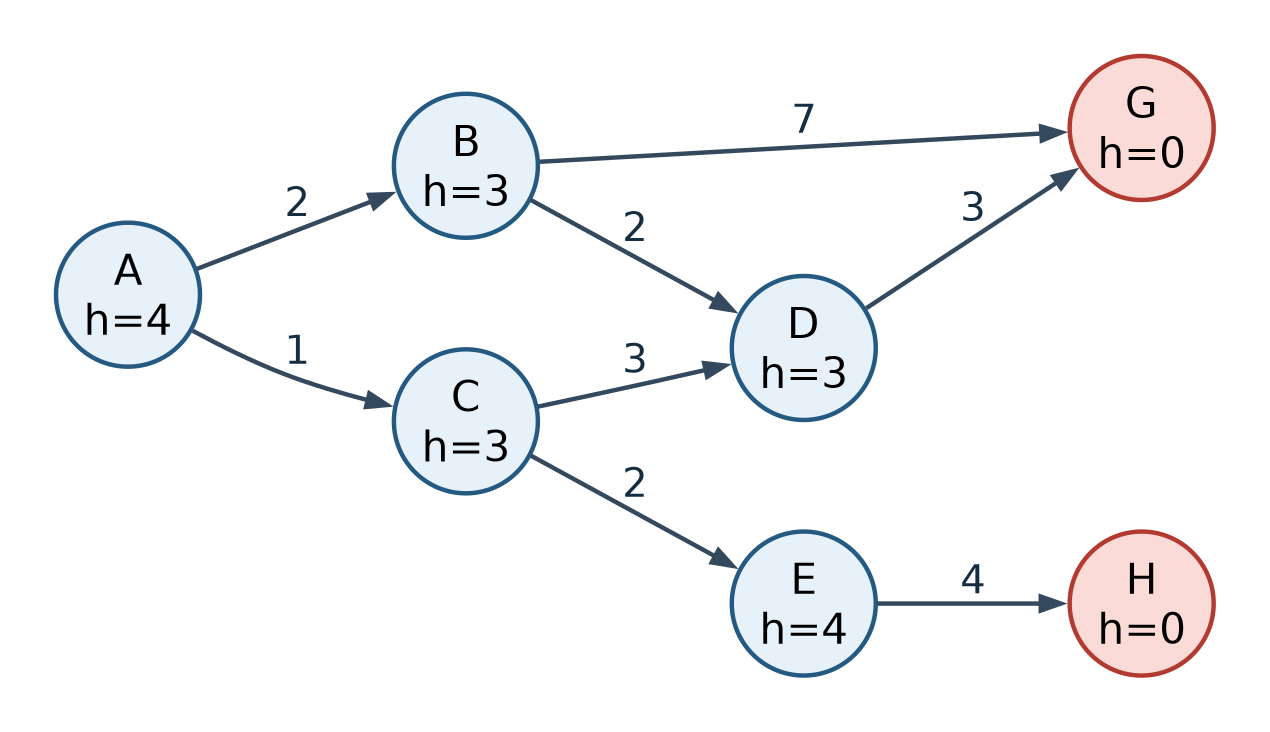

Los nodos rojos son los objetivos; `h` indica la estimación del coste restante.


| Isla | Destinos (coste) | Heurística |
|---|---|---:|
| A | B (2), C (1) | 4 |
| B | D (2), G (7) | 3 |
| C | D (3), E (2) | 3 |
| D | G (3) | 3 |
| E | H (4) | 4 |
| G, H | ninguno | 0 |

Simula DFS, BFS, coste uniforme, búsqueda voraz y A*. Indica el orden de expansión, el camino y el coste. En BFS y DFS considera los sucesores en orden alfabético; en las búsquedas por prioridad, resuelve los empates alfabéticamente. No vuelvas a expandir estados ya explorados. Si encuentras una ruta más barata a un estado aún pendiente, actualízala.

| Algoritmo | Orden de expansión | Camino | Coste |
|---|---|---|---:|
| DFS | | | |
| BFS | | | |
| Coste uniforme | | | |
| Voraz | | | |
| A* | | | |

## Torres de Hanói: ampliación

En el ejemplo resuelto se utilizan tres discos. Ahora trabaja con **cuatro discos**, inicialmente en la primera torre, y llévalos a la tercera. Solo se puede mover el disco superior y no puede quedar encima de un disco más pequeño.

Representa cada torre con una tupla ordenada de abajo hacia arriba. Reutiliza la idea de la BFS y de los padres del ejemplo, pero adapta los estados inicial y objetivo y comprueba los movimientos.

1. ¿Cómo representarías el estado del problema?

2. ¿Cuáles son los estados inicial y final?

3. ¿Qué acciones se pueden realizar desde un estado dado?

4. ¿Cuál sería el tamaño máximo del espacio de estados?

5. ¿Cómo comprobarías si un estado es el estado final?

6. Adapta la búsqueda del ejemplo a cuatro discos. Muestra la ruta, comprueba que todos los movimientos son válidos y compara el número mínimo de movimientos con el caso de tres discos.